# Import Library

Library yang akan digunakan:
- `pandas` untuk membaca dan mengolah data
- `numpy` untuk operasi numerik
- `matplotlib` untuk visualisasi
- `scikit-learn` untuk pembagian data, preprocessing, model, dan evaluasi

In [32]:
import numpy as np
import sklearn as sk
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.preprocessing import scale
import random
from sklearn.metrics import ConfusionMatrixDisplay

## Bagian 1 - EDA

### Membaca Dataset

In [33]:
df = pd.read_csv("dataset/creditcard.csv", low_memory=False)
df = df.sample(frac=1).reset_index(drop=True)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,35211.0,1.363342,-0.792046,1.141561,-0.492159,-1.671535,-0.514356,-1.196597,0.044551,-0.001483,...,0.298333,0.914018,-0.092509,0.433149,0.437014,-0.044379,0.046447,0.023755,6.70,0
1,70618.0,1.138068,0.168176,-0.011986,0.838160,0.037683,0.191980,-0.244405,0.190853,0.300872,...,-0.119256,-0.086043,-0.122040,-0.347818,0.499190,0.442462,0.015614,0.026890,12.31,0
2,137992.0,-0.159699,1.279812,0.206680,4.537197,-0.212131,0.555791,0.785852,0.394359,-2.649349,...,0.455462,0.920676,0.204707,0.071338,0.058816,0.556462,-0.192439,-0.119432,166.13,0
3,151975.0,1.770458,-0.045853,-0.446832,4.005957,0.006342,0.601232,-0.277376,0.210744,0.043425,...,0.092222,0.265687,0.074363,0.686999,0.035732,0.100965,-0.033924,-0.032968,69.20,0
4,153468.0,1.760024,-0.299060,-1.325048,0.771640,-0.589189,-1.729125,0.188732,-0.286559,1.114462,...,-0.135325,-0.393250,0.229114,0.732092,-0.269122,-0.147199,-0.027713,0.001944,107.59,0


In [34]:
frauds = df.loc[df['Class'] == 1]
non_fraunds = df.loc[df['Class'] == 0]
print("Kita mempunyai", len(frauds), "frauds data points and ", len(non_fraunds), "non frauds len data points.")

Kita mempunyai 492 frauds data points and  284315 non frauds len data points.


### Melihat Baris dan Kolom

In [35]:
print("Jumlah Baris: ", df.shape[0])
print("Jumlah Kolom: ", df.shape[1])

for col in df.columns:
    print ("-", col)

Jumlah Baris:  284807
Jumlah Kolom:  31
- Time
- V1
- V2
- V3
- V4
- V5
- V6
- V7
- V8
- V9
- V10
- V11
- V12
- V13
- V14
- V15
- V16
- V17
- V18
- V19
- V20
- V21
- V22
- V23
- V24
- V25
- V26
- V27
- V28
- Amount
- Class


In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

terlihat bahwa tidak ada data yang null

In [37]:
frauds = df.loc[df['Class'] == 1]
non_frauds = df.loc[df['Class'] == 0]
print(len(frauds), 'fraud data poiint')
print(len(non_frauds), 'non-fraud data point')

492 fraud data poiint
284315 non-fraud data point


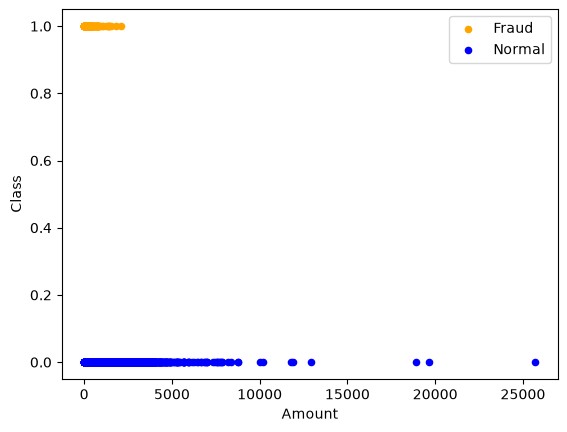

In [38]:
import matplotlib.pyplot as plt

ax = frauds.plot.scatter(x='Amount', y='Class', color='Orange', label='Fraud')
non_frauds.plot.scatter(x='Amount', y='Class', color='Blue', label='Normal', ax=ax)
plt.show()

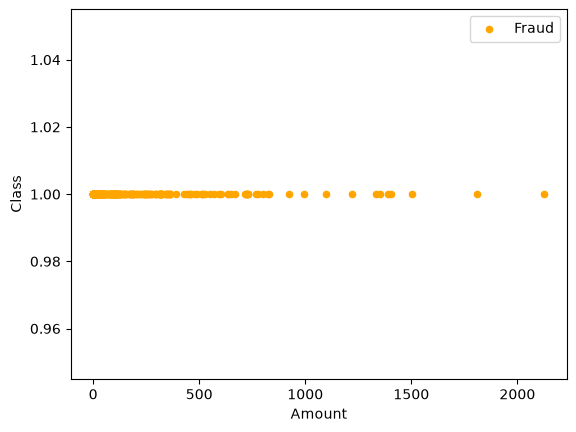

In [39]:

bx = frauds.plot.scatter(x='Amount', y='Class', color='Orange', label='Fraud')
plt.show()

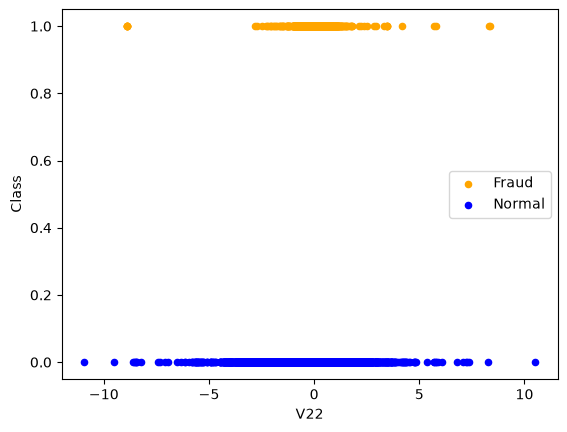

In [40]:
ax = frauds.plot.scatter(x='V22', y='Class', color='Orange', label='Fraud')
non_frauds.plot.scatter(x='V22', y='Class', color='Blue', label='Normal', ax=ax)
plt.show()

## Logistic Regression

In [41]:
from sklearn import datasets, linear_model
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split

In [42]:
X = df.iloc[:,:-1]
y = df['Class']


print('Ukuran X dan y secara berurutan adalah ,', len(X), len(y))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.35)

print('Ukuran data latih (training) dan data uji (testing) secara berurutan', len(X_train), len(y_train), "|", len(X_test), len(y_test))
print("Total number of frauds:", len(y.loc[df['Class'] == 1]), len(y.loc[df['Class'] == 1])/len(y))
print("Number of frauds on y_test:", len(y_test.loc[df['Class'] == 1]), len(y_test.loc[df['Class'] == 1]) / len(y_test))
print("Number of frauds on y_train:", len(y_train.loc[df['Class'] == 1]), len(y_train.loc[df['Class'] == 1])/len(y_train))

Ukuran X dan y secara berurutan adalah , 284807 284807
Ukuran data latih (training) dan data uji (testing) secara berurutan 185124 185124 | 99683 99683
Total number of frauds: 492 0.001727485630620034
Number of frauds on y_test: 176 0.0017655969423071136
Number of frauds on y_train: 316 0.001706963980899289


In [48]:
logistic = linear_model.LogisticRegression(C=1e5, max_iter=500)
logistic.fit(X_train, y_train)
print('score: ', logistic.score(X_test, y_test))

score:  0.9990269153215694


c:\Users\Ibnu Riski\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [60]:

y_predicted = np.array(logistic.predict(X_test))
y_right = np.array(y_test)

Accuracy: 0.9990

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     99507
       Fraud       0.83      0.56      0.67       176

    accuracy                           1.00     99683
   macro avg       0.92      0.78      0.84     99683
weighted avg       1.00      1.00      1.00     99683



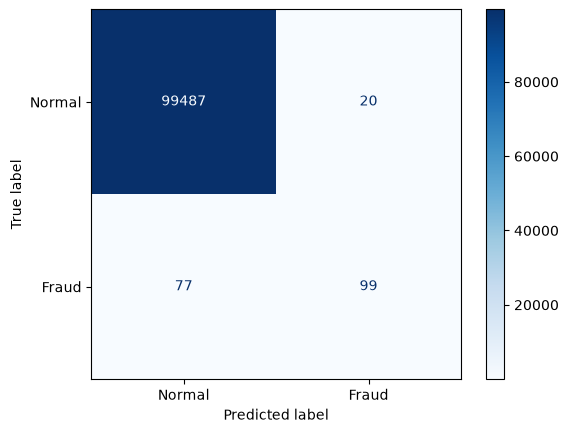

False Negative Rate (FNR): 0.4375


AttributeError: 'function' object has no attribute 'print_stats'

In [ ]:
import matplotlib.pyplot as plt
# Tambahkan 'confusion_matrix' di baris import
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Hitung akurasi
accuracy = accuracy_score(y_right, y_predicted)  # Pastikan variabelnya 'y_predicted'
print(f"Accuracy: {accuracy:.4f}")

# 2. Cetak laporan klasifikasi (Precision, Recall, F1-Score)
print("\nClassification Report:")
print(classification_report(y_right, y_predicted, target_names=['Normal', 'Fraud']))

# 3. Hitung dan tampilkan Confusion Matrix
cm = confusion_matrix(y_right, y_predicted)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Fraud'])
disp.plot(cmap="Blues")
plt.show()

# 4. Tambahan: Menghitung False Negative Rate (FNR)
tn, fp, fn, tp = cm.ravel()
fnr = fn / (fn + tp)
print(f"False Negative Rate (FNR): {fnr:.4f}")